## VINDPROGNOSE BERGEN
Hvor mye strøm kan en vindturbin ved Bergen produsere, og kan vi forutsi produksjonen fra værdata?

In [35]:
import requests
import pandas as pd
import matplotlib.pyplot as plt

## Hente data

Vi henter vindhastighet time for time i 10 og 120 meters høyde fra Open-Meteo sitt historiske arkiv.

In [31]:
def hent_vinddata(start, slutt, lat=60.39, lon=5.32):
    url = "https://archive-api.open-meteo.com/v1/archive"
    params = {
        "latitude": lat,
        "longitude": lon,
        "hourly": "wind_speed_10m,wind_speed_120m",
        "start_date": start,
        "end_date": slutt,
        "wind_speed_unit": "ms",
        "timezone": "Europe/Oslo"
    }

    svar = requests.get(url, params=params)
    if svar.status_code != 200:
        raise Exception(f"Feil fra API-et: {svar.status_code} {svar.text}")

    data = svar.json()
    
    df = pd.DataFrame(data["hourly"])
    df["time"] = pd.to_datetime(df["time"])
    return df

In [32]:
df = hent_vinddata("2025-01-01", "2025-12-31")
print(df.shape)
print(df.isna().sum())

(8760, 3)
time               0
wind_speed_10m     0
wind_speed_120m    0
dtype: int64


Datasettet har 8760 timer (hele 2025) og ingen manglende verdier

## Utforske data

In [33]:
df["maaned"] = df["time"].dt.month
df

,time,wind_speed_10m,wind_speed_120m,maaned
0,2025-01-01 00:00:00,2.71,5.02,1
1,2025-01-01 01:00:00,2.52,4.74,1
2,2025-01-01 02:00:00,3.34,6.09,1
3,2025-01-01 03:00:00,3.32,6.25,1
4,2025-01-01 04:00:00,2.29,4.39,1
...,...,...,...,...
8755,2025-12-31 19:00:00,3.85,7.42,12
8756,2025-12-31 20:00:00,3.64,8.02,12
8757,2025-12-31 21:00:00,6.10,10.97,12
8758,2025-12-31 22:00:00,3.32,7.01,12


In [65]:
per_maaned = df.groupby("maaned")["wind_speed_120m"].mean()

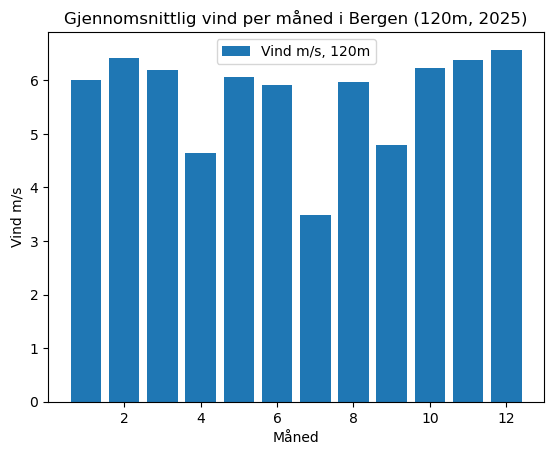

In [69]:
plt.bar(per_maaned.index, per_maaned.values, label = "Vind m/s, 120m")
plt.title("Gjennomsnittlig vind per måned i Bergen (120m, 2025)")
plt.xlabel("Måned")
plt.ylabel("Vind m/s")
plt.legend()
plt.savefig("grafer/vind_per_maaned.png", bbox_inches="tight")
plt.show()

In [1]:
#PROGNOSE 1

import pandas as pd
import requests

url = "https://api.open-meteo.com/v1/forecast"
params = {
    "latitude": 60.39,
    "longitude": 5.32,
    "hourly": "wind_speed_120m",
    "forecast_days": 3,
    "timezone": "Europe/Oslo"
}

svar = requests.get(url, params=params)
print(svar.status_code)   # 200 betyr at alt gikk bra
data = svar.json()        # gjør om JSON-svaret til Python-dictionaries
print(data)

200
{'latitude': 60.390038, 'longitude': 5.3183136, 'generationtime_ms': 0.028133392333984375, 'utc_offset_seconds': 3600, 'timezone': 'Europe/Oslo', 'timezone_abbreviation': 'GMT+1', 'elevation': 17.0, 'hourly_units': {'time': 'iso8601', 'wind_speed_120m': 'km/h'}, 'hourly': {'time': ['2026-11-25T00:00', '2026-11-25T01:00', '2026-11-25T02:00', '2026-11-25T03:00', '2026-11-25T04:00', '2026-11-25T05:00', '2026-11-25T06:00', '2026-11-25T07:00', '2026-11-25T08:00', '2026-11-25T09:00', '2026-11-25T10:00', '2026-11-25T11:00', '2026-11-25T12:00', '2026-11-25T13:00', '2026-11-25T14:00', '2026-11-25T15:00', '2026-11-25T16:00', '2026-11-25T17:00', '2026-11-25T18:00', '2026-11-25T19:00', '2026-11-25T20:00', '2026-11-25T21:00', '2026-11-25T22:00', '2026-11-25T23:00', '2026-11-26T00:00', '2026-11-26T01:00', '2026-11-26T02:00', '2026-11-26T03:00', '2026-11-26T04:00', '2026-11-26T05:00', '2026-11-26T06:00', '2026-11-26T07:00', '2026-11-26T08:00', '2026-11-26T09:00', '2026-11-26T10:00', '2026-11-26T1

In [2]:
df = pd.DataFrame(data["hourly"])
df["time"] = pd.to_datetime(df["time"])
df

,time,wind_speed_120m
0,2026-11-25 00:00:00,5.7
1,2026-11-25 01:00:00,4.6
2,2026-11-25 02:00:00,4.0
3,2026-11-25 03:00:00,4.2
4,2026-11-25 04:00:00,3.8
...,...,...
67,2026-11-27 19:00:00,41.7
68,2026-11-27 20:00:00,42.0
69,2026-11-27 21:00:00,40.9
70,2026-11-27 22:00:00,40.3


In [3]:
df["vind_ms"] = df["wind_speed_120m"] / 3.6
df["vind_ms"]

0      1.583333
1      1.277778
2      1.111111
3      1.166667
4      1.055556
        ...    
67    11.583333
68    11.666667
69    11.361111
70    11.194444
71    11.194444
Name: vind_ms, Length: 72, dtype: float64

In [4]:
def produksjon(vind):
    if vind < 3:
        return 0
    elif vind < 12:
        return 4 * ((vind - 3) / 9) ** 3
    elif vind < 25:
        return 4
    else:
        return 0

df["produksjon_mw"] = df["vind_ms"].apply(produksjon)
df

,time,wind_speed_120m,vind_ms,produksjon_mw
0,2026-11-25 00:00:00,5.7,1.583333,0.000000
1,2026-11-25 01:00:00,4.6,1.277778,0.000000
2,2026-11-25 02:00:00,4.0,1.111111,0.000000
3,2026-11-25 03:00:00,4.2,1.166667,0.000000
4,2026-11-25 04:00:00,3.8,1.055556,0.000000
...,...,...,...,...
67,2026-11-27 19:00:00,41.7,11.583333,3.469768
68,2026-11-27 20:00:00,42.0,11.666667,3.571813
69,2026-11-27 21:00:00,40.9,11.361111,3.207188
70,2026-11-27 22:00:00,40.3,11.194444,3.019194


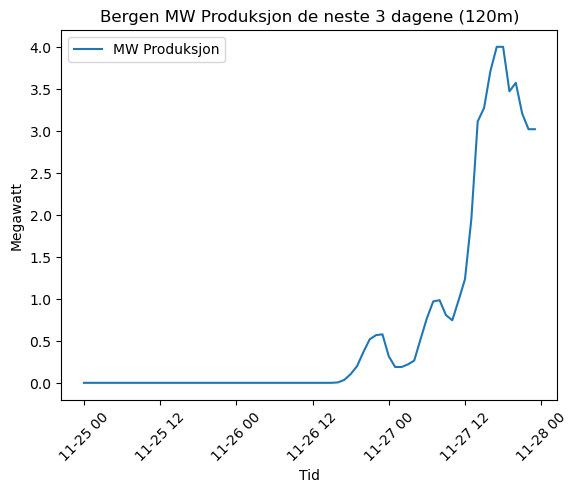

In [5]:
import matplotlib.pyplot as plt

plt.plot(df["time"], df["produksjon_mw"], label = "MW Produksjon")
plt.title("Bergen MW Produksjon de neste 3 dagene (120m)")
plt.xlabel("Tid")
plt.ylabel("Megawatt")
plt.legend()
plt.xticks(rotation=45)
plt.show()

In [6]:
#PROGNOSE 2

import pandas as pd
import requests

url = "https://archive-api.open-meteo.com/v1/archive"
params = {
    "latitude": 60.39,
    "longitude": 5.32,
    "hourly": "wind_speed_10m,wind_speed_120m",
    "start_date": "2026-09-01",
    "end_date": "2026-10-31",
    "timezone": "Europe/Oslo",
    "wind_speed_unit": "ms"
}

svar = requests.get(url, params=params)
print(svar.status_code)   # 200 betyr at alt gikk bra
data = svar.json()        # gjør om JSON-svaret til Python-dictionaries
print(data)

200
{'latitude': 60.42179, 'longitude': 5.294118, 'generationtime_ms': 0.2384185791015625, 'utc_offset_seconds': 3600, 'timezone': 'Europe/Oslo', 'timezone_abbreviation': 'GMT+1', 'elevation': 17.0, 'hourly_units': {'time': 'iso8601', 'wind_speed_10m': 'm/s', 'wind_speed_120m': 'm/s'}, 'hourly': {'time': ['2026-09-01T00:00', '2026-09-01T01:00', '2026-09-01T02:00', '2026-09-01T03:00', '2026-09-01T04:00', '2026-09-01T05:00', '2026-09-01T06:00', '2026-09-01T07:00', '2026-09-01T08:00', '2026-09-01T09:00', '2026-09-01T10:00', '2026-09-01T11:00', '2026-09-01T12:00', '2026-09-01T13:00', '2026-09-01T14:00', '2026-09-01T15:00', '2026-09-01T16:00', '2026-09-01T17:00', '2026-09-01T18:00', '2026-09-01T19:00', '2026-09-01T20:00', '2026-09-01T21:00', '2026-09-01T22:00', '2026-09-01T23:00', '2026-09-02T00:00', '2026-09-02T01:00', '2026-09-02T02:00', '2026-09-02T03:00', '2026-09-02T04:00', '2026-09-02T05:00', '2026-09-02T06:00', '2026-09-02T07:00', '2026-09-02T08:00', '2026-09-02T09:00', '2026-09-02T1

In [7]:
df = pd.DataFrame(data["hourly"])
df["time"] = pd.to_datetime(df["time"])
df

,time,wind_speed_10m,wind_speed_120m
0,2026-09-01 00:00:00,1.26,3.67
1,2026-09-01 01:00:00,0.94,3.31
2,2026-09-01 02:00:00,0.35,2.48
3,2026-09-01 03:00:00,0.14,1.73
4,2026-09-01 04:00:00,0.21,2.13
...,...,...,...
1459,2026-10-31 19:00:00,3.23,6.17
1460,2026-10-31 20:00:00,3.13,6.23
1461,2026-10-31 21:00:00,3.37,6.37
1462,2026-10-31 22:00:00,3.83,6.97


In [8]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error

X = df[["wind_speed_10m"]]   # doble klammer: X må være en tabell
y = df["wind_speed_120m"]    # enkle klammer: y er én kolonne

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, shuffle=False)

modell = LinearRegression()
modell.fit(X_train, y_train)

prediksjon = modell.predict(X_test)
print(mean_absolute_error(y_test, prediksjon))
print(mean_absolute_error(y_test, X_test["wind_speed_10m"]))

0.5095178349496148
3.2019453924914676


In [9]:
print(modell.coef_)       # a: stigningstallet
print(modell.intercept_)  # b: konstantleddet

[1.60161166]
0.779857448238169


In [10]:
df.loc[X_test.index, "prediksjon"] = prediksjon
test = df.loc[X_test.index]

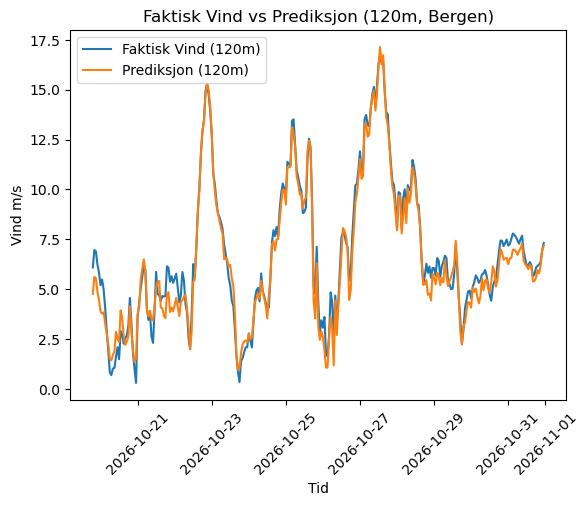

In [11]:
import matplotlib.pyplot as plt

plt.plot(test["time"], test["wind_speed_120m"], label = "Faktisk Vind (120m)")
plt.plot(test["time"], test["prediksjon"], label = "Prediksjon (120m)")
plt.title("Faktisk Vind vs Prediksjon (120m, Bergen)")
plt.xlabel("Tid")
plt.ylabel("Vind m/s")
plt.legend()
plt.xticks(rotation=45)
plt.show()